
# Lesson 12: Error Handling, Retries and Debugging

## Learning Objectives

By the end of this lesson, you will be able to:

- Handle exceptions inside LangGraph nodes.
- Retry operations that fail temporarily.
- Configure retry limits and backoff strategies.
- Implement fallback behavior.
- Debug failures in multi-step agent workflows.

## Why Does Error Handling Matter?

Agent workflows depend on multiple components:
- LLM APIs
- External tools
- Databases
- Network requests
- Python functions

Any of these components can fail.

A reliable agent should not immediately crash when a temporary failure occurs. It should handle the error, retry when appropriate, and provide a controlled outcome when recovery is unsuccessful.

## Our Practical Scenario

We will simulate an external service that fails temporarily.

Our LangGraph workflow will attempt to retrieve information, retry failed attempts, and eventually produce a successful result or handle repeated failures.



## 1. Simulating an External Service Failure

External APIs sometimes fail temporarily.

We will simulate this behavior using a Python function that raises an exception.

An **exception** is an error signal raised when Python cannot complete an operation normally.

For example:
- `ValueError`: Invalid value.
- `TimeoutError`: An operation took too long.
- `ConnectionError`: A connection failed.

We will deliberately raise a `ConnectionError` to simulate an unavailable external service.


In [1]:

def external_service():
    print("Calling external service...")
    raise ConnectionError("Service temporarily unavailable")

external_service()


Calling external service...


ConnectionError: Service temporarily unavailable


## 2. Handling Exceptions with Python

We can prevent an application from crashing by catching expected exceptions.

The `try` block contains the risky operation. The `except` block handles a matching exception and allows the program to continue.


In [2]:

try:
    external_service()

except ConnectionError as error:
    print("Caught an error:", error)
    print("The application can continue.")


Calling external service...
Caught an error: Service temporarily unavailable
The application can continue.



## 3. Manual Retry Logic

A retry means attempting the same operation again after a failure.

A retry limit prevents endless attempts.

We will allow a maximum of three attempts. Our simulated service will fail twice and succeed on the third attempt.


In [3]:

attempts = 0
max_attempts = 3

def unreliable_service():
    global attempts
    attempts += 1

    print(f"Attempt {attempts}")

    if attempts < 3:
        raise ConnectionError("Service temporarily unavailable")

    return "Data retrieved successfully!"


for attempt in range(max_attempts):
    try:
        result = unreliable_service()
        print(result)
        break

    except ConnectionError as error:
        print("Error:", error)

else:
    print("All retry attempts failed.")


Attempt 1
Error: Service temporarily unavailable
Attempt 2
Error: Service temporarily unavailable
Attempt 3
Data retrieved successfully!



## 4. LangGraph Built-in RetryPolicy

LangGraph allows us to attach a RetryPolicy to a node.

When the node raises a retryable exception, LangGraph automatically executes it again according to the configured policy.

This keeps retry logic separate from the node's main business logic.


In [4]:

from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import RetryPolicy


In [5]:

class ServiceState(TypedDict):
    result: str


In [6]:

service_attempts = 0

def fetch_data(state: ServiceState):
    global service_attempts
    service_attempts += 1

    print(f"Service attempt: {service_attempts}")

    if service_attempts < 3:
        raise ConnectionError("Service temporarily unavailable")

    return {"result": "Data retrieved successfully!"}


In [12]:

builder = StateGraph(ServiceState)

builder.add_node(
    "fetch",
    fetch_data,
    retry_policy=RetryPolicy(
        max_attempts=3,
        initial_interval=0.1,
        backoff_factor=1
    )
)

builder.add_edge(START, "fetch")
builder.add_edge("fetch", END)

retry_graph = builder.compile()


In [11]:

service_attempts = 0

result = retry_graph.invoke({"result": ""})

print("\nFinal result:", result)


Service attempt: 1
Service attempt: 2
Service attempt: 3

Final result: {'result': 'Data retrieved successfully!'}



## 5. Handling Exhausted Retries

A retry limit prevents infinite execution.

When all attempts fail, LangGraph propagates the final exception unless we explicitly handle it.

We will simulate a service that always fails and observe the behavior.


In [13]:

def permanently_failing_service(state: ServiceState):
    print("Attempting service call...")
    raise ConnectionError("Service is permanently unavailable")


builder = StateGraph(ServiceState)

builder.add_node(
    "fetch",
    permanently_failing_service,
    retry_policy=RetryPolicy(
        max_attempts=3,
        initial_interval=0.1,
        backoff_factor=1
    )
)

builder.add_edge(START, "fetch")
builder.add_edge("fetch", END)

failing_graph = builder.compile()


In [14]:

try:
    failing_graph.invoke({"result": ""})

except ConnectionError as error:
    print("\nWorkflow failed after retries:", error)


Attempting service call...
Attempting service call...
Attempting service call...

Workflow failed after retries: Service is permanently unavailable



## 6. Fallback Mechanism

A fallback is an alternative operation used when the primary operation fails.

Unlike retries, which repeat the same operation, a fallback switches to another source or strategy.

Examples:
- Primary LLM unavailable → use a backup LLM.
- Primary database unavailable → use a read replica, if appropriate.
- Primary search API fails → use cached results.

We will implement a primary service with retries and a fallback node.


In [20]:

def primary_service(state: ServiceState):
    print("Trying primary service...")
    raise ConnectionError("Primary service unavailable")


def fallback_service(state: ServiceState):
    print("Using fallback service...")
    return {"result": "Data retrieved from backup service."}


In [23]:

def safe_primary_service(state: ServiceState):
    try:
        return primary_service(state)
    except ConnectionError as error:
        print("Primary service failed:", error)
        return {"result": "primary_failed"}


def choose_service(state: ServiceState):
    if state["result"] == "primary_failed":
        return "fallback"

    return "end"



builder = StateGraph(ServiceState)

builder.add_node("primary", safe_primary_service)
builder.add_node("fallback", fallback_service)

# Always call the primary service first
builder.add_edge(START, "primary")

# Decide what to do after the primary service runs
builder.add_conditional_edges(
    "primary",
    choose_service,
    {
        "fallback": "fallback",
        "end": END
    }
)

builder.add_edge("fallback", END)

fallback_graph = builder.compile()


In [24]:

result = fallback_graph.invoke({"result": ""})
print("\nFinal result:", result)


Trying primary service...
Primary service failed: Primary service unavailable
Using fallback service...

Final result: {'result': 'Data retrieved from backup service.'}



## 7. Debugging LangGraph Workflows

Debugging means inspecting a workflow to understand what happened, where it happened, and why.

LangGraph provides streaming, state inspection, and graph visualization to help us understand execution.

We will use streaming and visualization to inspect our fallback workflow.


In [25]:

for update in fallback_graph.stream(
    {"result": ""},
    stream_mode="updates"
):
    print(update)


Trying primary service...
Primary service failed: Primary service unavailable
{'primary': {'result': 'primary_failed'}}
Using fallback service...
{'fallback': {'result': 'Data retrieved from backup service.'}}


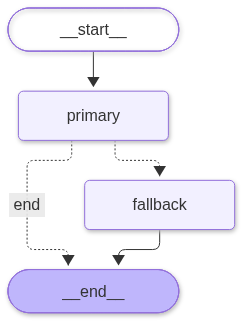

In [26]:

from IPython.display import Image, display

display(
    Image(fallback_graph.get_graph().draw_mermaid_png())
)



## 8. Streaming Modes: Updates vs Values

LangGraph supports different streaming modes.

- `updates`: Shows the state updates returned by individual nodes.
- `values`: Shows the full state after each graph step.

This distinction is useful when debugging complex workflows.


In [27]:

for update in fallback_graph.stream(
    {"result": ""},
    stream_mode="updates"
):
    print(update)


Trying primary service...
Primary service failed: Primary service unavailable
{'primary': {'result': 'primary_failed'}}
Using fallback service...
{'fallback': {'result': 'Data retrieved from backup service.'}}


In [28]:

for value in fallback_graph.stream(
    {"result": ""},
    stream_mode="values"
):
    print(value)


{'result': ''}
Trying primary service...
Primary service failed: Primary service unavailable
{'result': 'primary_failed'}
Using fallback service...
{'result': 'Data retrieved from backup service.'}
